# Linear Regression via Gradient Descent

Our data is sampled from an unknown PMF $p:\mathcal{X}\times{\mathcal{Y}}\rightarrow{[0,1]}$. In regression, we suppose further that our conditional probability $p:\mathcal{X}\rightarrow{(\mathcal{Y}\rightarrow{[0,1]})}$ is a statistical model $X\mapsto{Y = f(X) + \epsilon}$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

Initialising Linear Data

In [9]:
X = np.array([1,2,3,4,5])
Y = np.array([5,7,9,11,13])
n = len(X)

Initialising Linear Model

In [3]:
def linear_model(m, b):

    def predict(x):
        return m*x + b
    return predict

In [4]:
linear_model(2,3)(X)

array([ 5,  7,  9, 11, 13])

Initialising Loss function

In [7]:
def loss(m, b):
    return (1/n) * sum( val**2 for val in (Y-linear_model(m,b)(X)) )
def Loss(M, B):
    residuals = Y - (M[..., None] * X + B[..., None])
    return np.mean((Y - (M[..., None] * X + B[..., None]))**2, axis=-1)




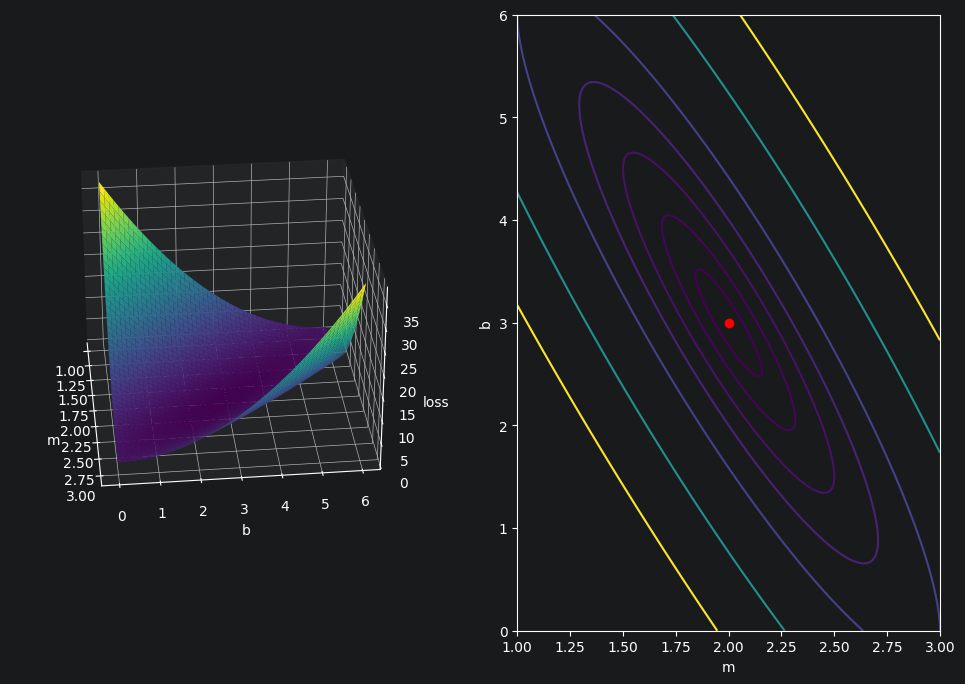

In [47]:
M = np.linspace(1,3,150)
B = np.linspace(0,6,150)
M, B = np.meshgrid(M,B)

fig = plt.figure(figsize=(12, 8))

ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(M, B, Loss(M,B), cmap='viridis', alpha=1, edgecolor='none')
ax1.view_init(elev=30, azim=-6)
ax1.set(xlabel='m', ylabel='b', zlabel='loss')

ax2 = fig.add_subplot(122)
ax2.contour(M, B, Loss(M, B),
           levels=[0.05, 0.2, 0.5, 1, 2, 5, 10])
ax2.set(xlabel='m', ylabel='b')
ax2.scatter(2,3, color='red')


Defining Gradient Descent Function

In [108]:
def grad_descent(x,y):
    m_curr, b_curr = (1, 1)
    iterations =1000
    learning_rate = 0.01

    fig = plt.figure(figsize=(12, 8))

    ax1 = fig.add_subplot(132, projection='3d')
    ax1.plot_surface(M, B, Loss(M,B), cmap='viridis', zorder=1, alpha=0.65, edgecolor='none')
    ax1.view_init(elev=30, azim=-6)
    ax1.set(xlabel='m', ylabel='b', zlabel='loss')

    ax2 = fig.add_subplot(133)
    ax2.contour(M, B, Loss(M, B),
                levels=[0.05, 0.2, 0.5, 1, 2, 5, 10], zorder=1)
    ax2.set(xlabel='m', ylabel='b')
    ax2.scatter(2,3, color='red')

    ax3 = fig.add_subplot(131)
    ax3.scatter(x, y, color='red', zorder=3)

    for i in range(iterations):
        linear_model(m_curr,b_curr)(X)
        d_m = -(2/n) * sum(x*(y-linear_model(m_curr,b_curr)(x)))
        d_b = -(2/n) * sum(y-linear_model(m_curr,b_curr)(x))
        m_curr = m_curr - learning_rate * d_m
        b_curr = b_curr - learning_rate * d_b
        print('m {}, b {}, iteration {}, loss {}'.format(m_curr, b_curr, i, loss(m_curr, b_curr)))
        color_idx = i / (iterations - 1)

        ax1.scatter(m_curr, b_curr, loss(m_curr, b_curr), color=plt.colormaps['plasma'](color_idx), zorder=10, alpha=1)
        ax2.scatter(m_curr,b_curr, color=plt.colormaps['plasma'](color_idx), zorder=3)
        ax3.plot(x, linear_model(m_curr,b_curr)(x), color=plt.colormaps['plasma'](color_idx), zorder=1)





m 1.34, b 1.1, iteration 0, loss 15.925599999999996
m 1.5992000000000002, b 1.1776, iteration 1, loss 9.470696319999997
m 1.79672, b 1.238096, iteration 2, loss 5.707815118335997
m 1.94715584, b 1.28553088, iteration 3, loss 3.513720004094772
m 2.0616497024, b 1.322990912, iteration 4, loss 2.233844357916914
m 2.148707313152, b 1.352832111616, iteration 5, loss 1.486739101406136
m 2.2148217775615997, b 1.37685303059456, iteration 6, loss 1.0501145382836428
m 2.264949804662374, b 1.3964266633289728, iteration 7, loss 0.7944311811025031
m 2.3028752478369134, b 1.412601141782651, iteration 8, loss 0.6441997727530545
m 2.3314866248058332, b 1.4261766040767831, iteration 9, loss 0.5554288549018322
m 2.352988971103943, b 1.4377638745068975, iteration 10, loss 0.5024823273716005
m 2.369065564990662, b 1.447829258750523, iteration 11, loss 0.47042068438431583
m 2.381001385167685, b 1.4567287396760729, iteration 12, loss 0.4505378662010728
m 2.38977735605023, b 1.4647340817724903, iteration 13,

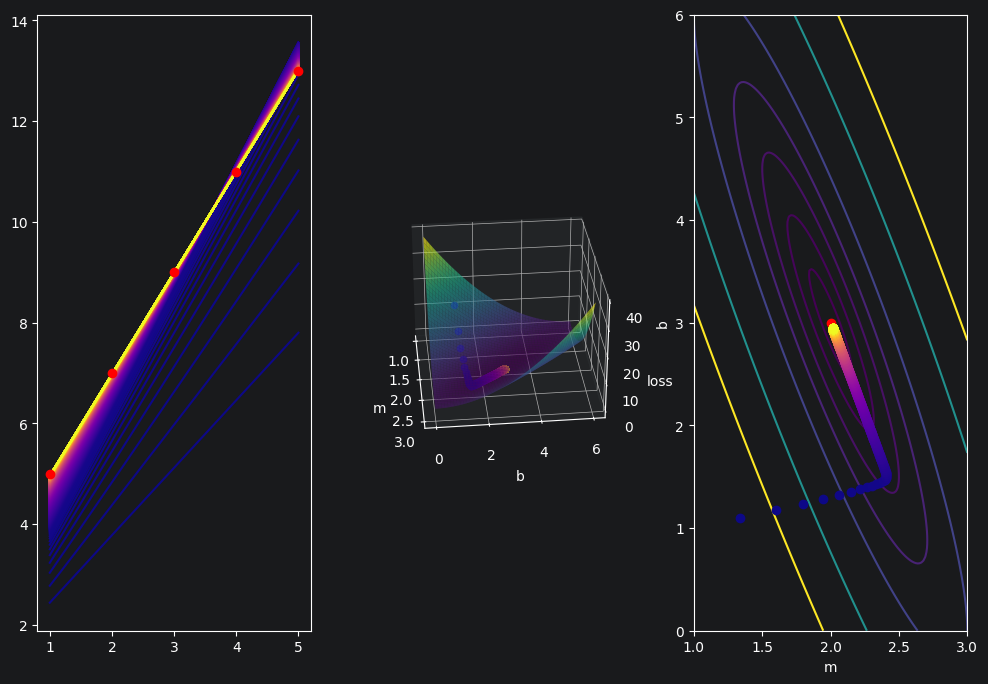

In [109]:
grad_descent(X, Y)